# 현실의 데이터 03: 영화 · 동영상 추천

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/03_movie_ratings.ipynb)

**분야**: 커머스 · 콘텐츠 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 개인화 추천 · 평점 예측 · 콜드 스타트

> 610명이 영화 9천 편에 남긴 별점 10만 개. 아직 안 본 영화에 몇 점을 줄까?

**데이터**: MovieLens (ml-latest-small) (약 1MB). GroupLens Research, University of Minnesota (Harper & Konstan, 2015). 610명 · 9,742편 · 별점 100,836개 (0.5~5점).

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | (사용자, 영화) 쌍 하나 |
| ② 입력 X | 사용자 번호 · 영화 번호 (+ 장르) |
| ③ 출력 y | 별점 (0.5~5) |
| ④ 평가지표 | RMSE (별 몇 개만큼 틀리나) |
| ⑤ 기준선 | 전체 평균 별점 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Harper & Konstan (2015) The MovieLens Datasets: History and Context, ACM TiiS](https://doi.org/10.1145/2827872)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
z = zipfile.ZipFile(download(URL, "data/ml-latest-small.zip"))
ratings = pd.read_csv(z.open("ml-latest-small/ratings.csv"))
movies = pd.read_csv(z.open("ml-latest-small/movies.csv"))
print(ratings.shape, movies.shape)
ratings.merge(movies, on="movieId").head()

(100836, 4) (9742, 3)


,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


## 열어 보기

사용자 × 영화 표로 보면 얼마나 비어 있을까? 영화마다 받은 별점 수는?

users 610, movies 9724, ratings 100836
filled share of the user x movie table: 1.70%
ratings per movie: median 3 | movies with only 1 rating: 3446


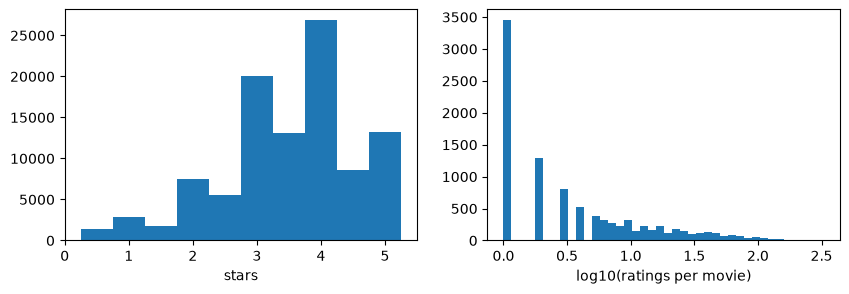

In [3]:
n_users, n_movies = ratings["userId"].nunique(), ratings["movieId"].nunique()
print(f"users {n_users}, movies {n_movies}, ratings {len(ratings)}")
print(f"filled share of the user x movie table: {len(ratings) / (n_users * n_movies):.2%}")
per_movie = ratings.groupby("movieId").size()
print("ratings per movie: median", int(per_movie.median()), "| movies with only 1 rating:", (per_movie == 1).sum())
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].hist(ratings["rating"], bins=np.arange(0.25, 5.5, 0.5)); axs[0].set_xlabel("stars")
axs[1].hist(np.log10(per_movie), bins=40); axs[1].set_xlabel("log10(ratings per movie)")
plt.show()

## 문제 하나 골라 보기: (사용자, 영화) → 별점

기준선 = 전체 평균. 조금 나은 방법 = **평균 + 사용자 치우침 + 영화 치우침** (후하게 주는 사람, 다들 좋아하는 영화). 시험은 무작위 20%.

In [4]:
from sklearn.model_selection import train_test_split

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))

def fit_biases(train, reg=5.0):
    """Global mean + user bias + movie bias, shrunk toward 0 for users/movies with few ratings"""
    mu = train["rating"].mean()
    r = train.assign(res=train["rating"] - mu)
    b_movie = r.groupby("movieId")["res"].agg(lambda v: v.sum() / (len(v) + reg))
    r = r.assign(res=r["res"] - r["movieId"].map(b_movie))
    b_user = r.groupby("userId")["res"].agg(lambda v: v.sum() / (len(v) + reg))
    return mu, b_user, b_movie

def predict_biases(model, data):
    mu, b_user, b_movie = model
    return (mu + data["userId"].map(b_user).fillna(0) + data["movieId"].map(b_movie).fillna(0)).clip(0.5, 5)

train, test = train_test_split(ratings, test_size=0.2, random_state=0)
model = fit_biases(train)
print(f"baseline (global mean {train['rating'].mean():.2f}): RMSE {rmse(test['rating'], np.full(len(test), train['rating'].mean())):.3f}")
print(f"mean + user bias + movie bias : RMSE {rmse(test['rating'], predict_biases(model, test)):.3f}")
print(f"movies in test never seen in train: {(~test['movieId'].isin(train['movieId'])).sum()}")

baseline (global mean 3.50): RMSE 1.051
mean + user bias + movie bias : RMSE 0.878
movies in test never seen in train: 828


## 다른 문제로 바꿔 보기

- **추천은 순위 문제**: 실제 서비스는 별점이 아니라 '첫 화면에 보여 줄 10편' 을 고른다. y 를 '다음에 볼 영화', 지표를 '상위 10편 안에 들었나 (hit@10)' 로 바꾸면?
- **콜드 스타트**: 시험에 처음 보는 영화가 있다. 별점이 없는 새 영화는 무엇으로 추천할까? (`movies.csv` 의 장르)
- **시간 순서**: 무작위가 아니라 사용자마다 마지막 20% 를 시험으로 두면 점수가 어떻게 바뀔까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |